# Portfolio 1 — Assignment 1: Waste Object Detection

## Task 1: Dataset Analysis and Designing the Training Pipeline

This notebook covers **Task 1 only**: inspect the Garbage Detection Dataset and design a documented YOLOv5 pipeline. It does not train or evaluate a model. Assignment 1 asks us to analyze data properties, create/verify train-validation-test subsets, choose preprocessing and augmentation, and justify training settings.

## 1. Dataset Analysis

### 1.1 Paths, class names, and label format

The prepared dataset should contain `train`, `val`, and `test` folders, each with `images/` and `labels/`. Each YOLO label row has `class_id x_center y_center width height`, with normalized coordinates. The YAML configuration defines split locations and class IDs.

In [1]:
from pathlib import Path
from collections import Counter
import hashlib
import math
import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# Resolve paths when launched from either the project root or notebooks/.
roots = [Path.cwd(), Path.cwd().parent]
PROJECT_ROOT = next((p.resolve() for p in roots if (p / 'data/processed/GarbageDataset/data.yaml').exists()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Could not locate data/processed/GarbageDataset/data.yaml')
DATASET_DIR = PROJECT_ROOT / 'data/processed/GarbageDataset'
DATA_YAML = DATASET_DIR / 'data.yaml'
with DATA_YAML.open(encoding='utf-8') as f:
    cfg = yaml.safe_load(f)
names = cfg['names']
CLASS_NAMES = ({int(k): str(v) for k, v in names.items()} if isinstance(names, dict) else dict(enumerate(names)))
SPLITS = {s: DATASET_DIR / cfg[s] for s in ('train', 'val', 'test')}
print('Project:', PROJECT_ROOT)
print('Classes:', CLASS_NAMES)
for split, folder in SPLITS.items(): print(f'{split:>5}: {folder} (exists={folder.is_dir()})')

Project: /Users/shreyas/Desktop/THWS/2nd sem/Computer Vision/Portfolio 1
Classes: {0: 'biodegradable', 1: 'cardboard', 2: 'glass', 3: 'metal', 4: 'paper', 5: 'plastic'}
train: /Users/shreyas/Desktop/THWS/2nd sem/Computer Vision/Portfolio 1/data/processed/GarbageDataset/train/images (exists=True)
  val: /Users/shreyas/Desktop/THWS/2nd sem/Computer Vision/Portfolio 1/data/processed/GarbageDataset/val/images (exists=True)
 test: /Users/shreyas/Desktop/THWS/2nd sem/Computer Vision/Portfolio 1/data/processed/GarbageDataset/test/images (exists=True)


### 1.2 Split sizes and annotation quality

Check that images have matching labels and that label rows are valid. A missing or malformed annotation can teach incorrect object locations or classes. Empty label files are counted separately because they can represent images with no labeled objects.

In [2]:
IMAGE_EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}
def inspect_split(name, image_dir):
    label_dir = image_dir.parent / 'labels'
    images = sorted(p for p in image_dir.glob('*') if p.suffix.lower() in IMAGE_EXTS)
    labels = sorted(label_dir.glob('*.txt')) if label_dir.exists() else []
    image_stems, label_stems = {p.stem for p in images}, {p.stem for p in labels}
    counts, boxes = Counter(), []
    malformed, bad_classes, bad_boxes = [], [], []
    empty = 0
    for path in labels:
        content = path.read_text(encoding='utf-8').strip()
        if not content:
            empty += 1; continue
        for row, line in enumerate(content.splitlines(), 1):
            parts = line.split()
            if len(parts) != 5:
                malformed.append((path.name, row, line)); continue
            try:
                cid = int(float(parts[0])); x, y, w, h = map(float, parts[1:])
            except ValueError:
                malformed.append((path.name, row, line)); continue
            if cid not in CLASS_NAMES: bad_classes.append((path.name, row, cid))
            if not all(np.isfinite([x,y,w,h])) or not (0 <= x <= 1 and 0 <= y <= 1 and 0 < w <= 1 and 0 < h <= 1):
                bad_boxes.append((path.name, row, (x,y,w,h)))
            counts[cid] += 1; boxes.append((w, h, math.sqrt(max(0, w*h))))
    return dict(name=name, images=images, n_images=len(images), n_labels=len(labels), counts=counts, boxes=boxes, empty=empty,
                missing=sorted(image_stems-label_stems), orphan=sorted(label_stems-image_stems), malformed=malformed,
                bad_classes=bad_classes, bad_boxes=bad_boxes)

stats = {s: inspect_split(s, folder) for s, folder in SPLITS.items()}
summary = pd.DataFrame([{'split':s, 'images':d['n_images'], 'label files':d['n_labels'],
    'objects':sum(d['counts'].values()), 'empty labels':d['empty'], 'missing labels':len(d['missing']),
    'orphan labels':len(d['orphan']), 'malformed rows':len(d['malformed']),
    'invalid class IDs':len(d['bad_classes']), 'invalid boxes':len(d['bad_boxes'])} for s,d in stats.items()]).set_index('split')
display(summary)
class_counts = pd.DataFrame({s:[d['counts'].get(cid,0) for cid in CLASS_NAMES] for s,d in stats.items()},
    index=[CLASS_NAMES[i] for i in CLASS_NAMES]); class_counts.index.name='class'
display(class_counts)

,images,label files,objects,empty labels,missing labels,orphan labels,malformed rows,invalid class IDs,invalid boxes
split,,,,,,,,,
train,7305,7305,50898,0,0,0,0,0,0
val,2113,2113,15654,0,0,0,0,0,0
test,1046,1046,7521,0,0,0,0,0,0


,train,val,test
class,,,
biodegradable,31040,10100,4255
cardboard,3274,899,523
glass,5437,1330,1042
metal,4094,1134,613
paper,3038,778,571
plastic,4015,1413,517


### 1.3 Class balance, object scale, and image variation

Count annotated objects per class because one image may contain multiple objects. Class imbalance can bias learning toward common categories. Small boxes can be difficult to detect after resizing. Review the charts and sample images before fixing augmentation strength or input size.

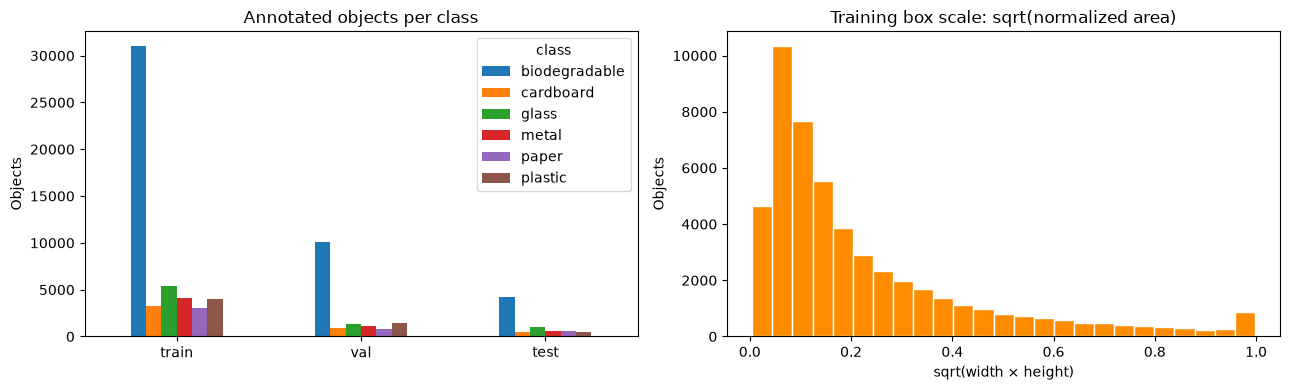

,width,height
count,7305.0,7305.0
mean,416.0,416.0
std,0.0,0.0
min,416.0,416.0
25%,416.0,416.0
50%,416.0,416.0
75%,416.0,416.0
max,416.0,416.0


Training class object counts, ascending:


,objects
class,
paper,3038
cardboard,3274
plastic,4015
metal,4094
glass,5437
biodegradable,31040


Fraction with sqrt(normalized area) < 0.1: 0.359


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
class_counts.T.plot(kind='bar', ax=ax[0]); ax[0].set_title('Annotated objects per class'); ax[0].set_ylabel('Objects'); ax[0].tick_params(axis='x', rotation=0)
train_boxes = np.asarray(stats['train']['boxes'], dtype=float)
if train_boxes.size:
    ax[1].hist(train_boxes[:,2], bins=25, color='darkorange', edgecolor='white')
    ax[1].set_title('Training box scale: sqrt(normalized area)'); ax[1].set_xlabel('sqrt(width × height)'); ax[1].set_ylabel('Objects')
else: ax[1].text(.5,.5,'No boxes found',ha='center')
plt.tight_layout(); plt.show()

dimensions=[]
for p in stats['train']['images']:
    try:
        with Image.open(p) as im: dimensions.append((im.width,im.height))
    except Exception as e: print('Unreadable image:', p.name, e)
display(pd.DataFrame(dimensions,columns=['width','height']).describe().round(1))
print('Training class object counts, ascending:')
display(class_counts['train'].sort_values().to_frame('objects'))
if train_boxes.size: print('Fraction with sqrt(normalized area) < 0.1:', round(float(np.mean(train_boxes[:,2] < .1)),3))

### 1.4 Visual annotation check

Inspect ground-truth boxes on representative training images for clutter, occlusion, lighting, object size, and annotation consistency. YOLO letterboxing preserves image aspect ratio while padding to the model input size.

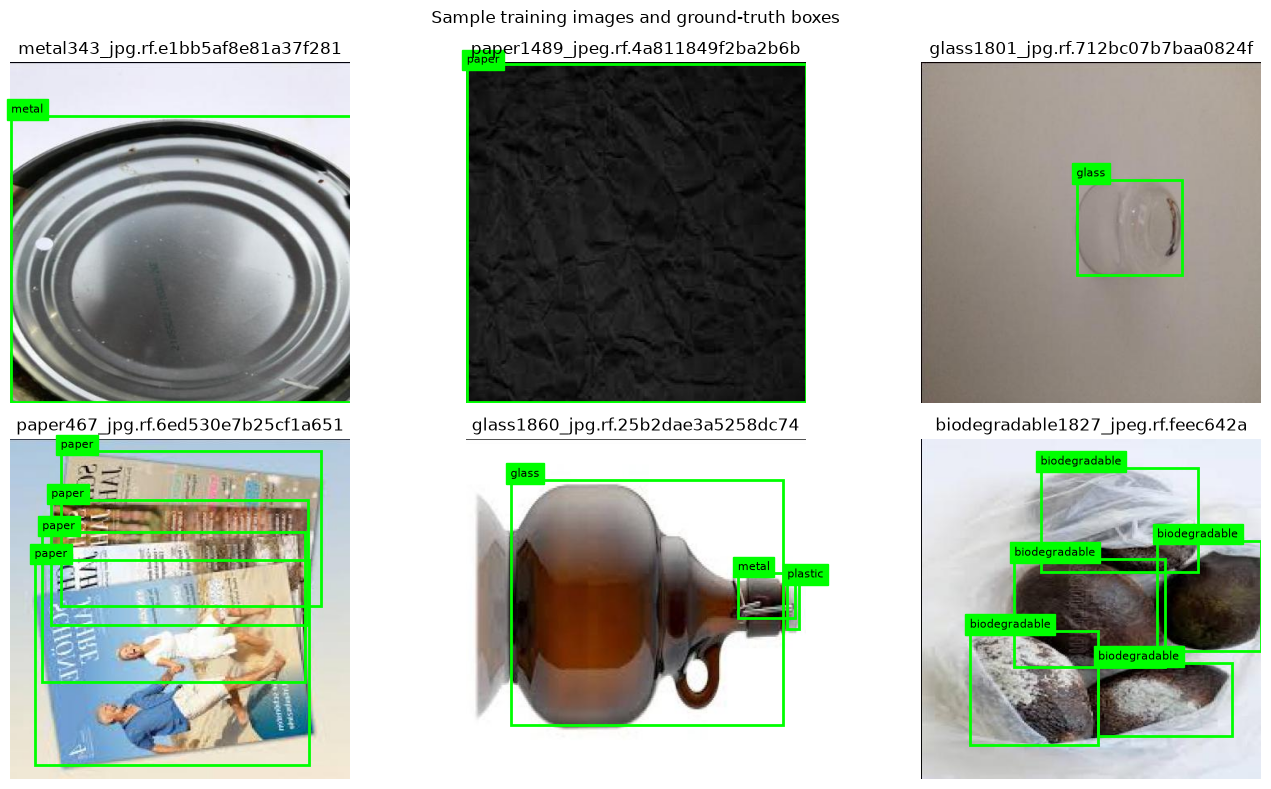

In [4]:
def show_boxes(image_path, ax):
    image = Image.open(image_path).convert('RGB'); W,H=image.size
    ax.imshow(image); ax.axis('off'); ax.set_title(image_path.name[:34])
    label = image_path.parent.parent / 'labels' / f'{image_path.stem}.txt'
    if not label.exists(): return
    for line in label.read_text(encoding='utf-8').splitlines():
        parts=line.split()
        if len(parts)!=5: continue
        cid,xc,yc,bw,bh=int(float(parts[0])),*map(float,parts[1:])
        x1,y1=(xc-bw/2)*W,(yc-bh/2)*H
        ax.add_patch(plt.Rectangle((x1,y1),bw*W,bh*H,fill=False,color='lime',linewidth=2))
        ax.text(x1,max(0,y1-4),CLASS_NAMES.get(cid,str(cid)),color='black',backgroundcolor='lime',fontsize=8)

images=stats['train']['images']
if images:
    rng=np.random.default_rng(42); sample=list(rng.choice(images,size=min(6,len(images)),replace=False))
    fig,axes=plt.subplots(2,3,figsize=(14,8))
    for ax,p in zip(axes.flat,sample): show_boxes(Path(p),ax)
    for ax in axes.flat[len(sample):]: ax.axis('off')
    plt.suptitle('Sample training images and ground-truth boxes'); plt.tight_layout(); plt.show()

### 1.5 Verify split separation

The project README reports 7,305 training, 2,113 validation, and 1,046 test images (approximately 70/20/10). This notebook verifies the current files. Keep validation for tuning and checkpoint selection; do not use test results to change training decisions. Exact hashes can reveal duplicate files crossing splits; near-duplicates may still need manual review.

In [5]:
def file_hash(path):
    h=hashlib.sha256()
    with path.open('rb') as f:
        for chunk in iter(lambda:f.read(1024*1024),b''): h.update(chunk)
    return h.hexdigest()
hashes={s:{file_hash(p):p.name for p in d['images']} for s,d in stats.items()}
for a,b in [('train','val'),('train','test'),('val','test')]:
    shared=set(hashes[a]) & set(hashes[b]); print(f'Exact duplicate files {a}/{b}: {len(shared)}')
    if shared: print('Examples:',[(hashes[a][h],hashes[b][h]) for h in list(shared)[:5]])
total=sum(d['n_images'] for d in stats.values())
for s,d in stats.items(): print(f"{s}: {d['n_images']:,}/{total:,} = {d['n_images']/max(total,1):.1%}")

Exact duplicate files train/val: 0
Exact duplicate files train/test: 0
Exact duplicate files val/test: 0
train: 7,305/10,464 = 69.8%
val: 2,113/10,464 = 20.2%
test: 1,046/10,464 = 10.0%


## 2. Findings and Design Implications

The README describes 10,464 images and six classes: biodegradable, cardboard, glass, metal, paper, and plastic. Its class mapping should be verified against the original dataset documentation; the local YAML currently maps IDs 0–5 in this order. Run the inspection cells and use their output to finalize these observations:

- Record annotation issues (missing/orphan labels, malformed rows, invalid IDs/boxes) and resolve them before training.
- Identify class imbalance from object counts. If substantial, consider class-aware sampling or targeted augmentation on training data only, and report class-wise results later.
- If many objects are small or image sizes vary, 640-pixel inputs with letterbox resizing are a reasonable starting point.
- Retain the separate partitions and investigate any duplicate overlap. Never tune on the test set.

## 3. Proposed YOLOv5 Training Pipeline

### 3.1 Detector choice

Use **YOLOv5s with pretrained COCO weights**. It is a single-stage detector and a practical speed/capacity balance for this six-class task and laptop-scale project. Record the exact YOLOv5 source version or commit and the pretrained checkpoint for reproducibility. The project README currently discusses YOLOv8, but this plan follows the requested YOLOv5. The existing YOLO label rows can be reused after confirming their class IDs and YAML paths.

### 3.2 Split, preprocessing, and augmentation

- **Split:** retain the existing train/validation/test partitions after integrity and duplicate checks.
- **Training preprocessing:** RGB decoding and YOLOv5 letterbox resize to 640 × 640, preserving aspect ratio and adjusting boxes consistently.
- **Training augmentation:** start with mosaic, horizontal flip, modest scale/translation, and HSV color augmentation. These represent variation in placement and lighting. Inspect examples and reduce transformations if they distort category cues or create unrealistic waste objects. Apply random augmentation only to training data.
- **Validation/test preprocessing:** deterministic resizing only, without random augmentation.

### 3.3 Initial training settings and selection

These are proposed starting values for the later training task, not training results. Adjust only from training/validation evidence and available memory.

| Setting | Starting value | Justification |
|---|---:|---|
| Model | YOLOv5s, pretrained | Transfer learning with compact detector |
| Image size | 640 | More detail for small or thin objects |
| Epochs | 50 maximum | Allows fine-tuning with early stopping |
| Batch size | 16, reduce if memory is insufficient | Practical starting point for laptop |
| Optimizer | YOLOv5 default SGD and schedule | Reproducible baseline using standard defaults |
| Early stopping | Patience 10 epochs | Stop when validation no longer improves |
| Seed | 42 | Reproducibility |
| Best checkpoint | Highest validation mAP@0.5:0.95 | Uses localization-sensitive validation metric |
| Final test | Once after model selection | Prevents tuning to test performance |

Record hardware, software versions, YOLOv5 commit, command/configuration, and deviations. For Task 2 report precision, recall, mAP@0.5, mAP@0.5:0.95, overall and per class.

### 3.4 Configuration summary (planning only)

This cell collects the design in one place. It deliberately does not invoke YOLOv5 or start training.

In [6]:
PIPELINE_PLAN = {
    'detector': 'YOLOv5s',
    'initialization': 'pretrained COCO checkpoint',
    'dataset_yaml': str(DATA_YAML),
    'classes': [CLASS_NAMES[i] for i in sorted(CLASS_NAMES)],
    'split_policy': 'verified existing train/val/test; test only for final evaluation',
    'image_size': 640, 'epochs_max': 50, 'batch_size_start': 16,
    'optimizer': 'YOLOv5 default SGD and learning-rate schedule',
    'early_stopping_patience': 10, 'seed': 42,
    'augmentations': ['mosaic', 'horizontal flip', 'modest scale/translation', 'HSV color'],
    'checkpoint_selection': 'best validation mAP@0.5:0.95',
    'training_started': False,
}
display(pd.Series(PIPELINE_PLAN, name='proposed value').to_frame())

,proposed value
detector,YOLOv5s
initialization,pretrained COCO checkpoint
dataset_yaml,/Users/shreyas/Desktop/THWS/2nd sem/Computer V...
classes,"[biodegradable, cardboard, glass, metal, paper..."
split_policy,verified existing train/val/test; test only fo...
image_size,640
epochs_max,50
batch_size_start,16
optimizer,YOLOv5 default SGD and learning-rate schedule
early_stopping_patience,10


## 4. Task 1 Conclusion

After running the analysis, summarize the actual split counts, label-quality checks, class balance, and object/image characteristics here. Explain any changes to the proposed settings based on the evidence. The designed pipeline uses the verified partitions, pretrained YOLOv5s, 640-pixel letterboxed images, training-only augmentation, validation-based checkpoint selection, and an untouched test set for final evaluation.

**Scope:** this notebook addresses Assignment 1, Task 1. Model training, test metrics, detection visualizations, and error analysis are Tasks 2 and 3.

## 4. Assignment 1 — Task 2: Model Training and Evaluation

### YOLOv5 setup and training

The cells use official YOLOv5 v7.0, pretrained yolov5s weights, and the existing dataset configuration. The repository is cloned only if missing. Training is opt-in; set RUN_TRAINING=True when ready. Validation is used during training for model selection, while the test split remains untouched until evaluation. See the official [YOLOv5 train.py](https://github.com/ultralytics/yolov5/blob/v7.0/train.py) and [val.py](https://github.com/ultralytics/yolov5/blob/v7.0/val.py).

In [7]:
import subprocess, sys, importlib, torch
YOLOV5_DIR = PROJECT_ROOT / 'yolov5'
if not (YOLOV5_DIR / 'train.py').exists():
    if YOLOV5_DIR.exists():
        raise FileExistsError(f'{YOLOV5_DIR} exists but is not a YOLOv5 checkout.')
    subprocess.run(['git','clone','--branch','v7.0','--depth','1',
                    'https://github.com/ultralytics/yolov5.git',str(YOLOV5_DIR)],check=True)
DEVICE = 'mps' if getattr(torch.backends,'mps',None) and torch.backends.mps.is_available() else 'cpu'
print('YOLOv5 v7.0:',YOLOV5_DIR,'| device:',DEVICE,'| torch:',torch.__version__)

Cloning into '/Users/shreyas/Desktop/THWS/2nd sem/Computer Vision/Portfolio 1/yolov5'...


YOLOv5 v7.0: /Users/shreyas/Desktop/THWS/2nd sem/Computer Vision/Portfolio 1/yolov5 | device: mps | torch: 2.15.0


Note: switching to '915bbf294bb74c859f0b41f1c23bc395014ea679'.

You are in 'detached HEAD' state. You can look around, make experimental
changes and commit them, and you can discard any commits you make in this
state without impacting any branches by switching back to a branch.

If you want to create a new branch to retain commits you create, you may
do so (now or later) by using -c with the switch command. Example:

  git switch -c <new-branch-name>

Or undo this operation with:

  git switch -

Turn off this advice by setting config variable advice.detachedHead to false



### Train YOLOv5s

Starting settings: image size 640, 50 epochs maximum, patience 10, batch size 16, seed 42, and 2 workers. If MPS runs out of memory, reduce the batch size (for example, to 8) and record that. The best validation checkpoint is saved to runs/train/waste_yolov5s/weights/best.pt.

In [8]:
RUN_TRAINING = False  # Set True when ready; training can take a while.
IMAGE_SIZE, BATCH_SIZE, EPOCHS = 640, 16, 50
TRAIN_PROJECT = PROJECT_ROOT / 'runs' / 'train'
TRAIN_NAME = 'waste_yolov5s'
BEST_WEIGHTS = TRAIN_PROJECT / TRAIN_NAME / 'weights' / 'best.pt'
cmd = [sys.executable,'train.py','--weights','yolov5s.pt','--data',str(DATA_YAML),
       '--img',str(IMAGE_SIZE),'--batch-size',str(BATCH_SIZE),'--epochs',str(EPOCHS),
       '--patience','10','--device',DEVICE,'--workers','2','--seed','42',
       '--project',str(TRAIN_PROJECT),'--name',TRAIN_NAME,'--exist-ok']
if RUN_TRAINING:
    subprocess.run(cmd,cwd=YOLOV5_DIR,check=True)
    if not BEST_WEIGHTS.exists(): raise FileNotFoundError(BEST_WEIGHTS)
    print('Best checkpoint:',BEST_WEIGHTS)
else:
    print('Training not started; set RUN_TRAINING=True when ready.')

Training not started; set RUN_TRAINING=True when ready.


### Test-set evaluation

After choosing the best checkpoint using validation, evaluate the held-out test set once. YOLOv5 prints overall and per-class precision, recall, mAP@0.5, and mAP@0.5:0.95. Predictions and confidence scores are saved for Task 3. Avoid tuning from test results; if test findings change the model, a new test set is needed for an unbiased final estimate.

In [9]:
if not BEST_WEIGHTS.exists():
    raise FileNotFoundError('Train first or set BEST_WEIGHTS to an existing checkpoint.')
if str(YOLOV5_DIR) not in sys.path: sys.path.insert(0,str(YOLOV5_DIR))
val_run = importlib.import_module('val').run
TEST_OUTPUT = PROJECT_ROOT / 'results' / 'task2'
TEST_NAME = 'test_yolov5s'
test_results,test_maps,test_speed = val_run(
    data=str(DATA_YAML),weights=str(BEST_WEIGHTS),batch_size=8,imgsz=IMAGE_SIZE,
    task='test',device=DEVICE,workers=2,verbose=True,save_txt=True,save_conf=True,
    plots=True,project=str(TEST_OUTPUT),name=TEST_NAME,exist_ok=True,half=False)
metric_names=['precision','recall','mAP@0.5','mAP@0.5:0.95','box_loss','obj_loss','class_loss']
display(pd.Series(test_results,index=metric_names,name='test').to_frame().round(4))
display(pd.DataFrame({'mAP@0.5:0.95':[float(test_maps[i]) for i in sorted(CLASS_NAMES)]},
                     index=[CLASS_NAMES[i] for i in sorted(CLASS_NAMES)]).round(4))
PREDICTION_DIR=TEST_OUTPUT/TEST_NAME/'labels'

FileNotFoundError: Train first or set BEST_WEIGHTS to an existing checkpoint.

## 5. Assignment 1 — Task 3: Visualization and Error Analysis

### Match predictions and ground truth

The following analysis uses a fixed operating point (confidence ≥0.25, same-class IoU ≥0.50) to select examples. These TP/FP/FN counts are not mAP, which averages across confidence and IoU thresholds.

In [ ]:
from matplotlib.patches import Rectangle
CONF_THRESHOLD, IOU_THRESHOLD = 0.25, 0.50
TEST_LABEL_DIR = SPLITS['test'].parent/'labels'
TEST_IMAGES = sorted(p for p in SPLITS['test'].glob('*') if p.suffix.lower() in IMAGE_EXTS)

def load_rows(path,pred=False):
    result=[]
    if not path.exists(): return result
    for line in path.read_text().splitlines():
        a=line.split()
        if len(a)<(6 if pred else 5): continue
        try:
            c=int(float(a[0])); x,y,w,h=map(float,a[1:5]); conf=float(a[5]) if pred else 1.
            if pred and conf<CONF_THRESHOLD: continue
            result.append({'c':c,'b':np.array([x-w/2,y-h/2,x+w/2,y+h/2]),'conf':conf})
        except ValueError: pass
    return result

def iou(a,b):
    x1,y1,x2,y2=max(a[0],b[0]),max(a[1],b[1]),min(a[2],b[2]),min(a[3],b[3])
    inter=max(0,x2-x1)*max(0,y2-y1)
    aa=max(0,a[2]-a[0])*max(0,a[3]-a[1]); ab=max(0,b[2]-b[0])*max(0,b[3]-b[1])
    return inter/max(aa+ab-inter,1e-12)

def analyze(path):
    gt=load_rows(TEST_LABEL_DIR/f'{path.stem}.txt')
    pr=load_rows(PREDICTION_DIR/f'{path.stem}.txt',True)
    pairs=[]
    for pi,p in enumerate(pr):
        for gi,g in enumerate(gt):
            v=iou(p['b'],g['b'])
            if v>=IOU_THRESHOLD: pairs.append((p['c']==g['c'],v,p['conf'],pi,gi))
    pairs.sort(reverse=True)  # prefer same-class, then best IoU/confidence
    usedp,usedg=set(),set()
    for same,v,conf,pi,gi in pairs:
        if pi in usedp or gi in usedg: continue
        usedp.add(pi); usedg.add(gi)
        pr[pi]['status']='tp' if same else 'wrong'
        gt[gi]['status']='matched' if same else 'wrong'
    for g in gt: g.setdefault('status','miss')
    for p in pr: p.setdefault('status','fp')
    return {'path':path,'gt':gt,'pr':pr,'tp':sum(x['status']=='tp' for x in pr),
            'miss':sum(x['status']=='miss' for x in gt),
            'bad':sum(x['status'] in ('wrong','fp') for x in pr)}

analysis=[analyze(p) for p in TEST_IMAGES]
display(pd.DataFrame([{'true positives':r['tp'],'misses':r['miss'],'incorrect predictions':r['bad']}
                      for r in analysis]).sum().to_frame('test count'))

### Show 2–3 examples per case

Green boxes are correct predictions, red boxes are false or wrong-class predictions, cyan boxes mark matched ground truth, and orange dashed boxes mark missed ground truth.

In [ ]:
def show_examples(case,n=3):
    key={'correct':'tp','missed':'miss','incorrect':'bad'}[case]
    chosen=sorted((r for r in analysis if r[key]),key=lambda r:(-r[key],r['path'].name))[:n]
    print(f'{case}: showing {len(chosen)} examples')
    if not chosen: return
    fig,axs=plt.subplots(1,len(chosen),figsize=(6*len(chosen),5),squeeze=False)
    for ax,r in zip(axs[0],chosen):
        im=Image.open(r['path']).convert('RGB'); W,H=im.size
        ax.imshow(im); ax.axis('off'); ax.set_title(r['path'].name[:28])
        for g in r['gt']:
            x1,y1,x2,y2=g['b']*np.array([W,H,W,H]); miss=g['status']=='miss'
            ax.add_patch(Rectangle((x1,y1),x2-x1,y2-y1,fill=False,
                         color='orange' if miss else 'cyan',linestyle='--' if miss else '-',linewidth=2))
        for p in r['pr']:
            x1,y1,x2,y2=p['b']*np.array([W,H,W,H]); good=p['status']=='tp'
            name=CLASS_NAMES.get(p['c'],str(p['c']))
            ax.add_patch(Rectangle((x1,y1),x2-x1,y2-y1,fill=False,color='lime' if good else 'red',linewidth=2))
            ax.text(x1,y1,f'{name} {p["conf"]:.2f}',backgroundcolor='lime' if good else 'salmon',fontsize=8)
    plt.tight_layout(); plt.show()

show_examples('correct')
show_examples('missed')
show_examples('incorrect')

### Error analysis and possible improvements

Use the figures and class-wise metrics to write 2–3 concrete observations:

- Which categories, object sizes, and scenes were detected correctly?
- Are misses small, occluded, crowded, poorly lit, or inconsistently annotated? Low recall suggests missed objects.
- Do false alarms or wrong classes involve visually similar materials, clutter, poor localization, or a low confidence threshold?
- Discuss limits such as imbalance, limited visual variety, and annotation noise. Separate observations from hypotheses.
- Possible improvements include adding/correcting examples, training-only targeted sampling or augmentation, and tuning image size/augmentation using validation only. Do not tune on the test set.

Connect each proposed improvement to the metric that indicates the issue.